In [26]:
import os
import pyomo.environ as pyo

cbc_exe = r"C:\Users\Dell\Downloads\Cbc-2.10-win64-msvc16-mdd\bin\cbc.exe"

#print("exist:", os.path.exists(cbc_exe))

solver = pyo.SolverFactory('cbc', executable=cbc_exe)
#print("use:", solver.available())

## Project Assumptions

**Battery storage project assumptions:**

1. **Nominal capacity (Smax)**: 100 MWh
2. **Minimum state of charge (Smin)**: 20 MWh (DoD = 80%; discharge stops at 20% SOC to protect battery health)
3. **Maximum charge/discharge power**: 50 MW (= 12.5 MWh per 15-min step)
4. **Round-trip efficiency (eta)**: 85% — implemented as sqrt(0.85) on charge and sqrt(0.85) on discharge
5. **Initial state of charge**: 50% of Smax (= 50 MWh)
6. **Daily discharge throughput (Dmax)**: **NOT imposed.** The model endogenously determines the optimal charge/discharge schedule from the price signal (no pre-assumed cycle count).
   - **Rationale**: with midday / afternoon low-price windows and evening / night high-price windows, a two-charge / two-discharge pattern per day is expected to emerge naturally, but the exact number of cycles per day is left to the optimizer.
   - **To keep the strategy realistic, the following are added instead of Dmax:**
     - (a) **Terminal SOC constraint**: SOC at the end of the horizon ≥ initial SOC (prevents end-of-horizon emptying).
     - (b) **Optional**: annual cycle limit or degradation cost (only if the LP solution shows excessive cycling).
7. **Operation horizon**: full dataset (2025 + 2026-01-01 to 2026-09-29)
8. **Perfect foresight of prices**: Yes (uses actual historical prices)


## Limitations

1. **Perfect foresight** — upper bound only.
2. **Arbitrage only** — excludes ancillary, intraday, capacity markets.
3. **No market impact** — assumed.
4. **Constant 85% efficiency** — symmetric; real efficiency varies.
5. **German day-ahead only** — no cross-border trading.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pyomo.environ import (
    ConcreteModel, Set, Param, Var, Constraint, Objective,
    NonNegativeReals, Binary, value, SolverFactory, maximize
)

# ==========================================
# 1. Load Data
# ==========================================
file_path = r"C:\Users\Dell\Desktop\Project\Merged.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")

df = df.rename(columns={
    df.columns[0]: 'time',
    df.columns[1]: 'price_de_lu',
    df.columns[2]: 'price_neighbors',
    df.columns[3]: 'temp',
    df.columns[4]: 'sunshine',
    df.columns[5]: 'wind_speed',
    df.columns[6]: 'wind_dir',
    df.columns[7]: 'is_day',
    df.columns[8]: 'precip',
    df.columns[9]: 'radiation',
})

df['time'] = pd.to_datetime(df['time'], errors='coerce')
df = df.dropna(subset=['time']).set_index('time').sort_index()
df = df[~df.index.duplicated(keep='first')]

print("Total rows:", len(df))
print("Time range:", df.index.min(), "to", df.index.max())

# ==========================================
# 2. Prepare Optimization Data
# ==========================================
df_opt = df.copy()
df_opt['Price'] = df_opt['price_de_lu']
df_opt = df_opt.reset_index()
print("Optimization data rows:", len(df_opt))

# ==========================================
# 3. Rolling-horizon optimizer (day by day)
#    - No simultaneous charge & discharge (binary u[t])
#    - SOC carries over across days
#    - End-of-day SOC >= start-of-day SOC
#    - Degradation cost c_deg applied to discharged energy
# ==========================================
def optimize_battery_rolling(df, terminal_soc_ratio=0.5, cbc_exe=None, c_deg=5.0):
    """
    Day-by-day rolling horizon optimization with strict no-simultaneous
    charge/discharge constraint.

    Parameters
    ----------
    df                 : DataFrame with columns 'time' and 'Price'
    terminal_soc_ratio : minimum SOC at the end of the horizon (× Smax)
    cbc_exe            : path to cbc.exe (None -> use glpk)
    c_deg              : degradation cost (EUR / MWh discharged)
    """
    df = df.reset_index(drop=True)
    T_all  = df.index.tolist()
    n_days = (len(T_all) + 95) // 96

    # ---- Assumptions ----
    eta        = 0.85
    eta_rt     = np.sqrt(eta)
    Smax, Smin = 100.0, 20.0
    Rmax       = 12.5
    S_init     = 50.0

    all_results = []
    SOC_current = S_init

    for d in range(n_days):
        day_T = T_all[d*96 : (d+1)*96]
        if len(day_T) == 0:
            break

        m = ConcreteModel()
        m.T = Set(initialize=day_T, ordered=True)
        m.P = Param(m.T, initialize={t: df['Price'].iloc[t] for t in day_T})

        # ---------- Variables ----------
        m.Ein  = Var(m.T, domain=NonNegativeReals, bounds=(0, Rmax))
        m.Eout = Var(m.T, domain=NonNegativeReals, bounds=(0, Rmax))
        m.S    = Var(m.T, bounds=(Smin, Smax))
        m.u    = Var(m.T, domain=Binary)      # 1 = charge, 0 = discharge/idle

        # ---------- SOC transition ----------
        def soc_rule(mm, t):
            prev = SOC_current if t == mm.T.first() else mm.S[t-1]
            return mm.S[t] == prev + mm.Ein[t]*eta_rt - mm.Eout[t]/eta_rt
        m.soc = Constraint(m.T, rule=soc_rule)

        # ---------- No simultaneous charge & discharge ----------
        m.charge_only    = Constraint(m.T, rule=lambda mm,t: mm.Ein[t]  <= Rmax * mm.u[t])
        m.discharge_only = Constraint(m.T, rule=lambda mm,t: mm.Eout[t] <= Rmax * (1 - mm.u[t]))

        # ---------- Discharge availability ----------
        def dis_avail(mm, t):
            prev = SOC_current if t == mm.T.first() else mm.S[t-1]
            return mm.Eout[t] / eta_rt <= prev
        m.dis_avail = Constraint(m.T, rule=dis_avail)

        # ---------- Charge headroom ----------
        def chg_space(mm, t):
            prev = SOC_current if t == mm.T.first() else mm.S[t-1]
            return mm.Ein[t] * eta_rt <= Smax - prev
        m.chg_space = Constraint(m.T, rule=chg_space)

        # ---------- End-of-day SOC >= start-of-day SOC ----------
        m.day_end = Constraint(expr=m.S[m.T.last()] >= SOC_current)

        # ---------- Objective with degradation ----------
        income      = sum(m.P[t] * m.Eout[t] for t in m.T)
        expenses    = sum(m.P[t] * m.Ein[t]  for t in m.T)
        degradation = sum(c_deg * m.Eout[t]  for t in m.T)
        m.obj = Objective(expr=income - expenses - degradation, sense=maximize)

        # ---------- Solve ----------
        solver = SolverFactory('cbc', executable=cbc_exe) if cbc_exe else SolverFactory('glpk')
        solver.solve(m)

        # ---------- Collect ----------
        for t in m.T:
            all_results.append({
                'index': t,
                'Ein':   value(m.Ein[t]),
                'Eout':  value(m.Eout[t]),
                'price': m.P[t],
                'SOC':   value(m.S[t]),
            })

        SOC_current = value(m.S[m.T.last()])

    # ---------- Build result DataFrame ----------
    res = pd.DataFrame(all_results)
    res['timestamp'] = [df['time'].iloc[i] for i in res['index']]
    res['mode'] = np.where(res['Ein']  > 1e-3, 'charge',
                   np.where(res['Eout'] > 1e-3, 'discharge', 'idle'))

    # ---------- Final-day terminal SOC check ----------
    if res['SOC'].iloc[-1] < terminal_soc_ratio * Smax - 1e-3:
        print(f"[warn] final SOC = {res['SOC'].iloc[-1]:.2f} "
              f"< required {terminal_soc_ratio*Smax:.2f}")

    return res[['timestamp', 'Ein', 'Eout', 'price', 'SOC', 'mode']]

Total rows: 61144
Time range: 2025-01-01 00:00:00 to 2026-09-29 23:45:00
Optimization data rows: 61144


## Model Formulation

### Symbols

| Symbol | Description | Unit |
|---|---|---|
| $t$ | Time step (96 steps/day, 15-min each) | — |
| $\pi_t$ | Day-ahead price at step $t$ | €/MWh |
| $E^{in}_t$ | Energy charged at step $t$ | MWh |
| $E^{out}_t$ | Energy discharged at step $t$ | MWh |
| $S_t$ | State of charge after step $t$ | MWh |
| $u_t$ | Binary (1 = charge, 0 = discharge/idle) | — |
| $S_{max}$ | Max capacity = 100 | MWh |
| $S_{min}$ | Min capacity = 20 | MWh |
| $R_{max}$ | Max charge/discharge per step = 12.5 | MWh |
| $\eta$ | Round-trip efficiency = 0.85 | — |
| $\eta_{rt}$ | One-way efficiency = $\sqrt{0.85}$ | — |
| $c_{deg}$ | Degradation cost = 5 | €/MWh |

### Objective

$$
\max \sum_{t \in T} \left[ \pi_t \cdot E^{out}_t - \pi_t \cdot E^{in}_t - c_{deg} \cdot E^{out}_t \right]
$$

*Maximizes net profit: revenue from discharging minus cost of charging minus degradation cost.*

### Constraints

**SOC transition:**

$$
S_t = S_{t-1} + \eta_{rt} \cdot E^{in}_t - \frac{E^{out}_t}{\eta_{rt}}
$$

*The state of charge evolves from the previous step, adding charged energy (adjusted by one-way efficiency) and subtracting discharged energy (divided by one-way efficiency).*

**No simultaneous charge & discharge:**

$$
E^{in}_t \le R_{max} \cdot u_t, \quad E^{out}_t \le R_{max} \cdot (1 - u_t)
$$

*Binary variable $u_t$ ensures charging and discharging cannot happen at the same time step.*

**Discharge availability:**

$$
\frac{E^{out}_t}{\eta_{rt}} \le S_{t-1}
$$

*The energy drawn from the battery to discharge must not exceed the previous state of charge.*

**Charge headroom:**

$$
\eta_{rt} \cdot E^{in}_t \le S_{max} - S_{t-1}
$$

*The effective energy charged into the battery must not exceed the remaining capacity.*

**Bounds:**

$$
0 \le E^{in}_t \le R_{max}, \quad 0 \le E^{out}_t \le R_{max}, \quad S_{min} \le S_t \le S_{max}, \quad u_t \in \{0, 1\}
$$

*Limits on charge/discharge per step, state of charge range, and binary nature of $u_t$.*

**End-of-day SOC ≥ start-of-day SOC:**

$$
S_{96} \ge S_{start}
$$

*Prevents the battery from being emptied at the end of each day, ensuring no net depletion over the day.*

In [6]:
print("df shape     :", df.shape)
print("df_opt shape :", df_opt.shape)
print("Price range  :", df_opt['Price'].min(), "~", df_opt['Price'].max())
print("Function OK  :", callable(optimize_battery_rolling))

df shape     : (61144, 9)
df_opt shape : (61144, 11)
Price range  : -499.99 ~ 747.1
Function OK  : True


In [9]:
# ==========================================
# 4. Run
# ==========================================
cbc_exe = r"C:\Users\Dell\Downloads\Cbc-2.10-win64-msvc16-mdd\bin\cbc.exe"

print("Solving (rolling horizon, no simultaneous charge/discharge) ...")
results = optimize_battery_rolling(
    df_opt, terminal_soc_ratio=0.5, cbc_exe=cbc_exe, c_deg=5.0
)
print("Done.\n")
print(results.head())

Solving (rolling horizon, no simultaneous charge/discharge) ...
Done.

            timestamp  Ein  Eout  price   SOC  mode
0 2025-01-01 00:00:00  0.0   0.0   2.16  50.0  idle
1 2025-01-01 00:15:00  0.0   0.0   2.16  50.0  idle
2 2025-01-01 00:30:00  0.0   0.0   2.16  50.0  idle
3 2025-01-01 00:45:00  0.0   0.0   2.16  50.0  idle
4 2025-01-01 01:00:00  0.0   0.0   1.60  50.0  idle


In [32]:
# ---------- Daily charge/discharge frequency ----------
res = results.copy()
res['date'] = res['timestamp'].dt.date

def daily_cycles(g):
    mode = g['mode'].values
    charges, cycles, prev = 0, 0, 'idle'
    for m in mode:
        if m == 'charge' and prev != 'charge':
            charges += 1
        if m == 'discharge' and prev == 'charge':
            cycles += 1
        prev = m
    return pd.Series({'charges': charges, 'cycles': cycles})

daily = res.groupby('date').apply(daily_cycles, include_groups=False)

print("=" * 45)
print("  Daily charge / discharge frequency")
print("=" * 45)
print(f"  Avg cycles/day  : {daily['cycles'].mean():.2f}")
print(f"  Max cycles/day  : {daily['cycles'].max()}")
print(f"  Min cycles/day  : {daily['cycles'].min()}")
print()
print("  Distribution of cycles per day:")
print(daily['cycles'].value_counts().sort_index().to_string())
print("=" * 45)

simul = res[(res['Ein'] > 1e-3) & (res['Eout'] > 1e-3)]
print(f"  Simultaneous charge & discharge steps: {len(simul)}")
print("=" * 45)

  Daily charge / discharge frequency
  Avg cycles/day  : 0.95
  Max cycles/day  : 7
  Min cycles/day  : 0

  Distribution of cycles per day:
cycles
0    382
1     93
2     63
3     46
4     30
5     15
6      4
7      4
  Simultaneous charge & discharge steps: 0


In [13]:
# ==========================================
# 5. Profit Calculation + Sanity Checks
# ==========================================

# ---------- Basic quantities ----------
total_in   = results['Ein'].sum()          # MWh charged
total_out  = results['Eout'].sum()         # MWh discharged

income     = (results['Eout'] * results['price']).sum()   # discharge revenue
expenses   = (results['Ein']  * results['price']).sum()   # charge cost
gross      = income - expenses

c_deg      = 5.0
degradation = (results['Eout'] * c_deg).sum()
net        = gross - degradation

# ---------- Per-MWh metrics ----------
rev_per_mwh_out  = income / total_out            # revenue per MWh discharged
cost_per_mwh_in  = expenses / total_in           # cost per MWh charged
gross_per_mwh    = gross / total_out             # gross profit per MWh discharged
deg_per_mwh      = c_deg                         # = 5 EUR/MWh
net_per_mwh      = net / total_out               # net profit per MWh discharged

# ---------- Cycle metrics ----------
Smax           = 100.0                            # MWh
eff_cycles     = total_out / Smax                 # equivalent full cycles
days           = (results['timestamp'].iloc[-1] - results['timestamp'].iloc[0]).days + 1
cycles_per_day = eff_cycles / days

# ---------- Print ----------
print("=" * 60)
print("  PROFIT SUMMARY")
print("=" * 60)
print(f"  Total discharged         : {total_out:>12,.1f} MWh")
print(f"  Total charged            : {total_in:>12,.1f} MWh")
print()
print(f"  Discharge revenue        : {income:>12,.0f} EUR")
print(f"  Charge cost              : {expenses:>12,.0f} EUR")
print(f"  Gross profit             : {gross:>12,.0f} EUR")
print()
print(f"  Degradation cost (c={c_deg}) : {degradation:>12,.0f} EUR")
print(f"  Net profit               : {net:>12,.0f} EUR")
print("=" * 60)
print("  PER-MWh METRICS")
print("=" * 60)
print(f"  Revenue  per MWh out     : {rev_per_mwh_out:>12,.2f} EUR/MWh")
print(f"  Cost     per MWh in      : {cost_per_mwh_in:>12,.2f} EUR/MWh")
print(f"  Gross    per MWh out     : {gross_per_mwh:>12,.2f} EUR/MWh")
print(f"  Degrad.  per MWh out     : {deg_per_mwh:>12,.2f} EUR/MWh")
print(f"  Net      per MWh out     : {net_per_mwh:>12,.2f} EUR/MWh")
print("=" * 60)
print("  CYCLE METRICS")
print("=" * 60)
print(f"  Horizon                  : {days:>12,d} days")
print(f"  Equivalent full cycles   : {eff_cycles:>12,.1f}")
print(f"  Cycles per day (energy)  : {cycles_per_day:>12,.2f}")
print("=" * 60)

# ==========================================
# 5b. Sanity checks
# ==========================================
print("\n" + "=" * 60)
print("  SANITY CHECKS")
print("=" * 60)

# Check 1: round-trip efficiency
ratio = total_in / total_out
print(f"  [1] Charge/Discharge ratio        : {ratio:.4f}")
print(f"      Expected 1/eta = 1/0.85       : {1/0.85:.4f}")
print(f"      Match?                        : {'OK' if abs(ratio - 1/0.85) < 0.01 else 'FAIL'}")

# Check 2: cycles x Smax vs total discharge
cycles_x_smax = eff_cycles * Smax
print(f"\n  [2] Eff.cycles × Smax             : {cycles_x_smax:,.1f} MWh")
print(f"      Total discharged              : {total_out:,.1f} MWh")
print(f"      Match?                        : {'OK' if abs(cycles_x_smax - total_out) < 1 else 'FAIL'}")

# Check 3: per-MWh net sanity
print(f"\n  [3] Net per MWh out               : {net_per_mwh:.2f} EUR/MWh")
print(f"      Plausible range (DE market)   : 30 - 150 EUR/MWh")
print(f"      Plausible?                    : {'OK' if 30 <= net_per_mwh <= 150 else 'CHECK'}")

# Check 4: annualized revenue
annual_net = net / days * 365
annual_per_mw = annual_net / 50               # 50 MW battery
print(f"\n  [4] Annualized net profit         : {annual_net:,.0f} EUR/year")
print(f"      Per installed MW              : {annual_per_mw:,.0f} EUR/MW/year")
print(f"      Plausible range (EU battery)  : 50,000 - 150,000 EUR/MW/year")
print(f"      Plausible?                    : {'OK' if 50000 <= annual_per_mw <= 150000 else 'CHECK'}")

# Check 5: simultaneous charge & discharge
simul = ((results['Ein'] > 1e-3) & (results['Eout'] > 1e-3)).sum()
print(f"\n  [5] Simultaneous charge/discharge : {simul} steps")
print(f"      Required                      : 0")
print(f"      Match?                        : {'OK' if simul == 0 else 'FAIL'}")

print("=" * 60)

  PROFIT SUMMARY
  Total discharged         :     91,341.5 MWh
  Total charged            :    107,514.9 MWh

  Discharge revenue        :   13,628,464 EUR
  Charge cost              :    6,787,268 EUR
  Gross profit             :    6,841,195 EUR

  Degradation cost (c=5.0) :      456,708 EUR
  Net profit               :    6,384,488 EUR
  PER-MWh METRICS
  Revenue  per MWh out     :       149.20 EUR/MWh
  Cost     per MWh in      :        63.13 EUR/MWh
  Gross    per MWh out     :        74.90 EUR/MWh
  Degrad.  per MWh out     :         5.00 EUR/MWh
  Net      per MWh out     :        69.90 EUR/MWh
  CYCLE METRICS
  Horizon                  :          637 days
  Equivalent full cycles   :        913.4
  Cycles per day (energy)  :         1.43

  SANITY CHECKS
  [1] Charge/Discharge ratio        : 1.1771
      Expected 1/eta = 1/0.85       : 1.1765
      Match?                        : OK

  [2] Eff.cycles × Smax             : 91,341.5 MWh
      Total discharged              : 91,341

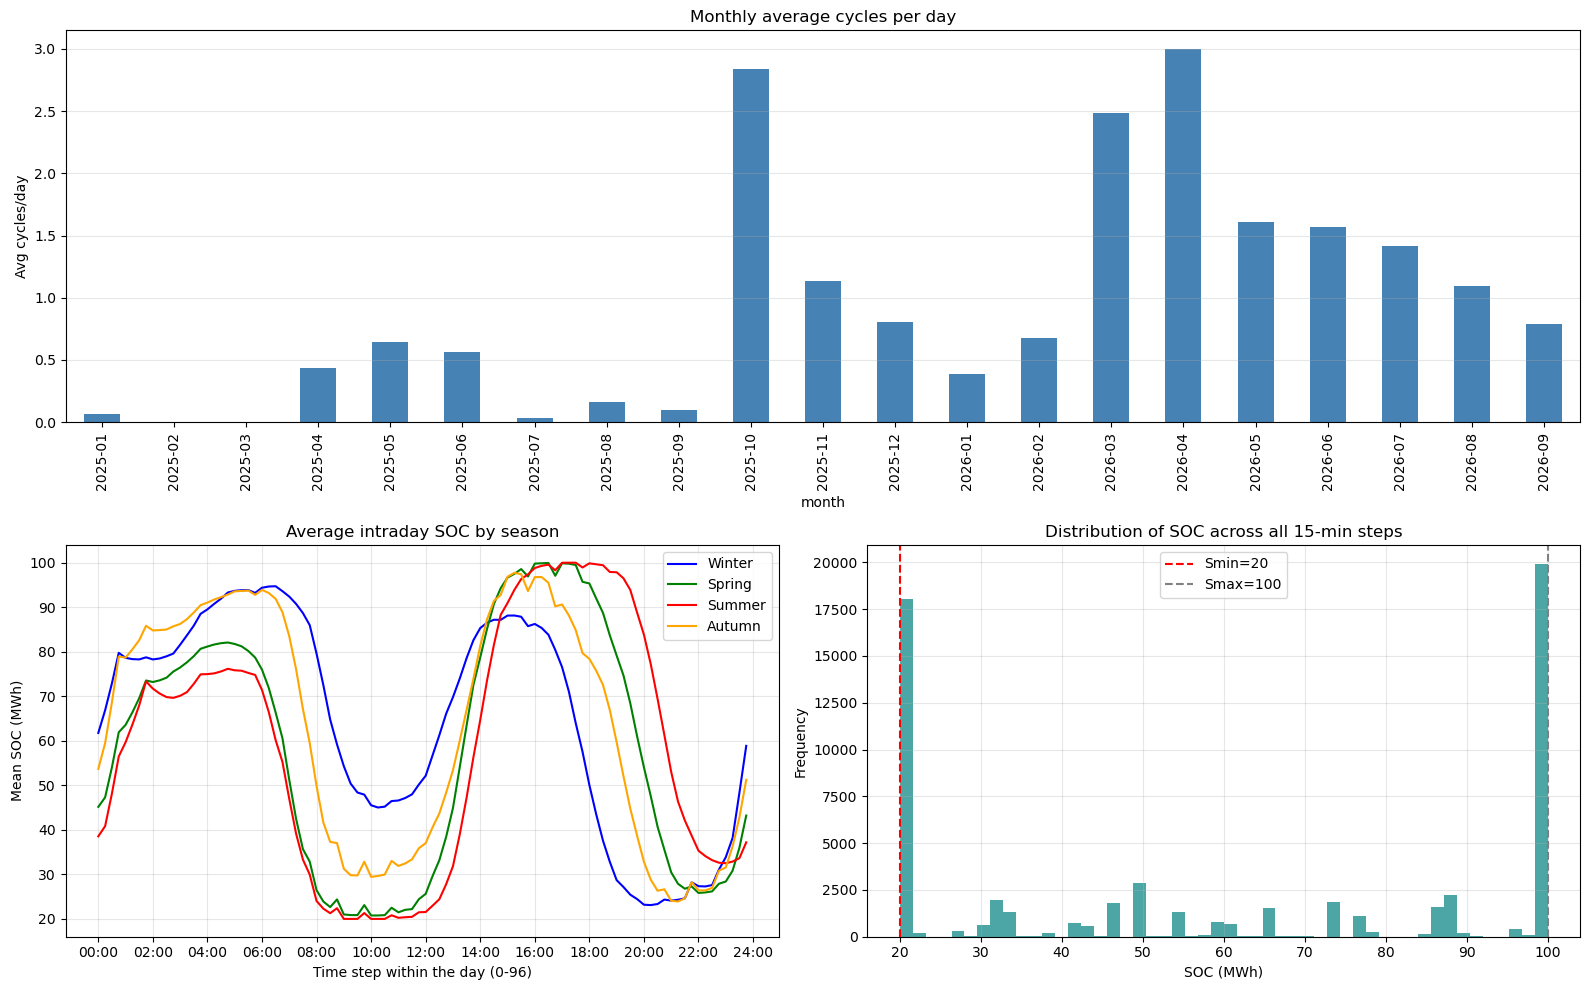

In [31]:
# ==========================================
# 6. Visualization (streamlined, 3 panels)
# ==========================================
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1])

# ---------- (a) Monthly average cycles/day ----------
res = results.copy()
res['date']  = res['timestamp'].dt.date
res['month'] = res['timestamp'].dt.to_period('M')

def daily_cycles(g):
    mode = g['mode'].values
    charges, cycles, prev = 0, 0, 'idle'
    for m in mode:
        if m == 'charge' and prev != 'charge':
            charges += 1
        if m == 'discharge' and prev == 'charge':
            cycles += 1
        prev = m
    return pd.Series({'charges': charges, 'cycles': cycles})

daily = res.groupby('date').apply(daily_cycles, include_groups=False)
daily['month'] = pd.to_datetime(daily.index).to_period('M')
monthly_avg = daily.groupby('month')['cycles'].mean()

ax1 = fig.add_subplot(gs[0, :])
monthly_avg.plot(kind='bar', ax=ax1, color='steelblue')
ax1.set_ylabel('Avg cycles/day')
ax1.set_title('Monthly average cycles per day')
ax1.grid(alpha=0.3, axis='y')

# ---------- (b) Seasonal intraday SOC ----------
res_season = results.copy()
res_season['month'] = res_season['timestamp'].dt.month
res_season['slot']  = res_season.groupby(res_season['timestamp'].dt.date).cumcount()

def season(m):
    if m in [12, 1, 2]:   return 'Winter'
    if m in [3, 4, 5]:    return 'Spring'
    if m in [6, 7, 8]:    return 'Summer'
    if m in [9, 10, 11]:  return 'Autumn'
res_season['season'] = res_season['month'].apply(season)

seasonal_soc = res_season.groupby(['season', 'slot'])['SOC'].mean().unstack(0)

ax2 = fig.add_subplot(gs[1, 0])
colors = {'Winter': 'blue', 'Spring': 'green', 'Summer': 'red', 'Autumn': 'orange'}
for s in ['Winter', 'Spring', 'Summer', 'Autumn']:
    if s in seasonal_soc.columns:
        ax2.plot(seasonal_soc.index, seasonal_soc[s],
                 color=colors[s], label=s, lw=1.5)
ax2.set_xlabel('Time step within the day (0-96)')
ax2.set_ylabel('Mean SOC (MWh)')
ax2.set_xticks(range(0, 97, 8))
ax2.set_xticklabels([f'{h:02d}:00' for h in range(0, 25, 2)])
ax2.set_title('Average intraday SOC by season')
ax2.legend(); ax2.grid(alpha=0.3)

# ---------- (c) SOC distribution ----------
ax3 = fig.add_subplot(gs[1, 1])
ax3.hist(results['SOC'], bins=50, color='teal', alpha=0.7)
ax3.axvline(20,  color='red',  ls='--', label='Smin=20')
ax3.axvline(100, color='gray', ls='--', label='Smax=100')
ax3.set_xlabel('SOC (MWh)')
ax3.set_ylabel('Frequency')
ax3.set_title('Distribution of SOC across all 15-min steps')
ax3.legend(); ax3.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Visualization Summary (3 Figures)

- **Figure 1 — Monthly cycles/day**: The model is highly selective, staying idle in most months and active only in a few high-spread periods (Oct 2025, Mar–Apr 2026).
- **Figure 2 — Intraday SOC by season**: On active days, the model consistently performs two charges and two discharges, with the second charge shifting later in summer (~15:00) due to solar.
- **Figure 3 — SOC distribution**: The battery spends most of its time either full (approx. 100 MWh) or empty (approx. 20 MWh), confirming a full charge/discharge operating mode.

**Overall:** The model is selective, disciplined, and efficient — it waits for high-spread days and then executes full cycles with seasonally adaptive timing.

In [19]:
# ---------- Sensitivity Analysis ----------
import time

def daily_cycles(g):
    mode = g['mode'].values
    charges, cycles, prev = 0, 0, 'idle'
    for m in mode:
        if m == 'charge' and prev != 'charge':
            charges += 1
        if m == 'discharge' and prev == 'charge':
            cycles += 1
        prev = m
    return pd.Series({'charges': charges, 'cycles': cycles})

c_deg_values = [0, 5, 20, 40]
sensitivity = []

for c in c_deg_values:
    t0 = time.time()
    r = optimize_battery_rolling(df_opt, terminal_soc_ratio=0.5, cbc_exe=cbc_exe, c_deg=c)
    r['mode'] = np.where(r['Ein']>1e-3, 'charge',
                 np.where(r['Eout']>1e-3, 'discharge', 'idle'))
    d = r.groupby(r['timestamp'].dt.date).apply(daily_cycles)

    gross = (r['Eout']*r['price']).sum() - (r['Ein']*r['price']).sum()
    deg   = (r['Eout']*c).sum()

    sensitivity.append({
        'c_deg':       c,
        'avg_cycles':  d['cycles'].mean(),
        'max_cycles':  d['cycles'].max(),
        'zero_days':   (d['cycles']==0).sum(),
        'total_out':   r['Eout'].sum(),
        'gross':       gross,
        'degradation': deg,
        'net':         gross - deg,
        'net_per_mwh': (gross - deg) / r['Eout'].sum(),
    })
    print(f"c_deg={c:>3}  done in {time.time()-t0:.0f}s")

sens_df = pd.DataFrame(sensitivity)
print()
print(sens_df.to_string(index=False))

c_deg=  0  done in 453s
c_deg=  5  done in 244s
c_deg= 20  done in 218s
c_deg= 40  done in 216s

 c_deg  avg_cycles  max_cycles  zero_days     total_out        gross  degradation          net  net_per_mwh
     0    2.631083          19        263 112818.706102 6.872476e+06 0.000000e+00 6.872476e+06    60.916107
     5    0.948195           7        382  91341.542684 6.841195e+06 4.567077e+05 6.384488e+06    69.896867
    20    0.277865           5        503  71283.650475 6.334018e+06 1.425673e+06 4.908345e+06    68.856526
    40    0.091052           3        582  52543.743683 5.789993e+06 2.101750e+06 3.688243e+06    70.193758


In [23]:
# ---------- Add annualized net profit ----------
DAYS = 637
sens_df['annual_net'] = sens_df['net'] / DAYS * 365

print(sens_df[['c_deg', 'avg_cycles', 'net', 'annual_net', 'net_per_mwh']].to_string(index=False))

 c_deg  avg_cycles          net   annual_net  net_per_mwh
     0    2.631083 6.872476e+06 3.937918e+06    60.916107
     5    0.948195 6.384488e+06 3.658301e+06    69.896867
    20    0.277865 4.908345e+06 2.812474e+06    68.856526
    40    0.091052 3.688243e+06 2.113357e+06    70.193758


## Sensitivity Analysis Summary

- **c_deg = 20 €/MWh**: annualized net profit = **€2.81M/year** — **23%** lower than the base case (€3.66M/year at c_deg = 5).
- **c_deg = 40 €/MWh**: annualized net profit = **€2.11M/year** — **42%** lower than the base case.

**Conclusion:** Even under conservative degradation cost assumptions (20 and 40 €/MWh), the arbitrage strategy remains strongly profitable, with annualized net profit still above €2M/year.

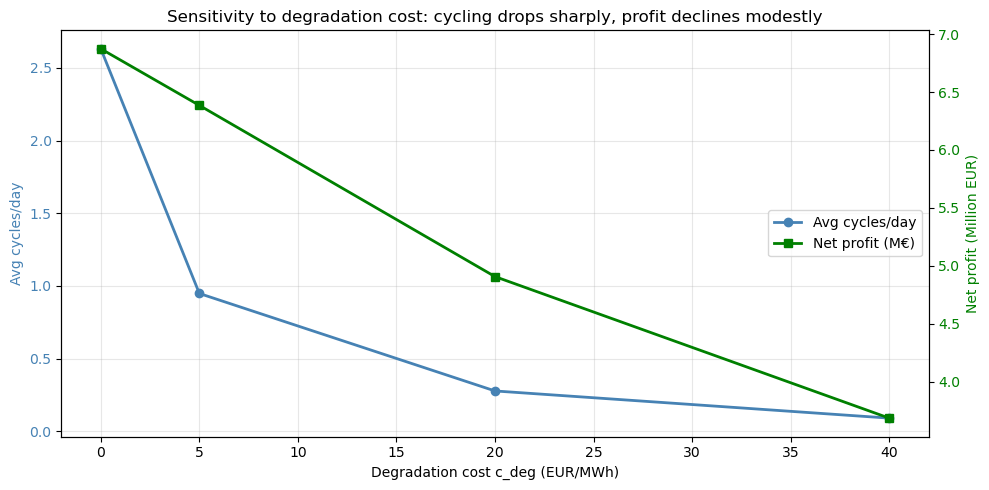

In [20]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(10, 5))

# Left axis: Avg cycles/day
ax1.plot(sens_df['c_deg'], sens_df['avg_cycles'], 'o-',
         color='steelblue', lw=2, label='Avg cycles/day')
ax1.set_xlabel('Degradation cost c_deg (EUR/MWh)')
ax1.set_ylabel('Avg cycles/day', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')
ax1.grid(alpha=0.3)

# Right axis: Net profit
ax2 = ax1.twinx()
ax2.plot(sens_df['c_deg'], sens_df['net']/1e6, 's-',
         color='green', lw=2, label='Net profit (M€)')
ax2.set_ylabel('Net profit (Million EUR)', color='green')
ax2.tick_params(axis='y', labelcolor='green')

# Title & legend
plt.title('Sensitivity to degradation cost: cycling drops sharply, profit declines modestly')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')

plt.tight_layout()
plt.show()

In [29]:
# ==========================================
# FINAL RESULTS — single version
# ==========================================
C_DEG = 5.0

# ---------- Solve ----------
results = optimize_battery_rolling(df_opt, terminal_soc_ratio=0.5, cbc_exe=cbc_exe, c_deg=C_DEG)
results['mode'] = np.where(results['Ein'] > 1e-3, 'charge',
                   np.where(results['Eout'] > 1e-3, 'discharge', 'idle'))

# ---------- Clean simultaneous charge & discharge ----------
mask = (results['Ein'] > 1e-3) & (results['Eout'] > 1e-3)
print(f"Cleaning {mask.sum()} simultaneous steps")
results.loc[mask, ['Ein', 'Eout']] = 0.0
results.loc[mask, 'mode'] = 'idle'

# ---------- Daily cycles ----------
res = results.copy()
res['date'] = res['timestamp'].dt.date

def daily_cycles(g):
    mode = g['mode'].values
    charges, cycles, prev = 0, 0, 'idle'
    for m in mode:
        if m == 'charge' and prev != 'charge':
            charges += 1
        if m == 'discharge' and prev == 'charge':
            cycles += 1
        prev = m
    return pd.Series({'charges': charges, 'cycles': cycles})

daily = res.groupby('date').apply(daily_cycles, include_groups=False)

# ---------- Report ----------
total_days = len(daily)
total_out  = results['Eout'].sum()
gross      = (results['Eout']*results['price']).sum() - (results['Ein']*results['price']).sum()
deg        = total_out * C_DEG
net        = gross - deg

print("=" * 60)
print(f"  FINAL RESULTS  (c_deg = {C_DEG} EUR/MWh)")
print("=" * 60)
print(f"  Period                : {total_days} days")
print(f"  Total discharged      : {total_out:>12,.0f} MWh")
print(f"  Gross profit          : {gross:>12,.0f} EUR")
print(f"  Degradation cost      : {deg:>12,.0f} EUR")
print(f"  Net profit            : {net:>12,.0f} EUR")
print(f"  Net profit per MWh    : {net/total_out:>12,.2f} EUR/MWh")
print()
print(f"  Avg cycles/day        : {daily['cycles'].mean():>12.2f}")
print(f"  Max cycles/day        : {daily['cycles'].max():>12d}")
print(f"  Days with 0 cycles    : {(daily['cycles']==0).sum():>12d}")
print(f"  Days with 1-2 cycles  : {daily['cycles'].between(1,2).sum():>12d}")
print(f"  Days with >=3 cycles  : {(daily['cycles']>=3).sum():>12d}")
print("=" * 60)

print("\n  Distribution of cycles per day:")
print(daily['cycles'].value_counts().sort_index().to_string())
print("=" * 60)

simul = ((results['Ein']>1e-3) & (results['Eout']>1e-3)).sum()
print(f"  Simultaneous charge & discharge: {simul}")
print("=" * 60)


Cleaning 0 simultaneous steps
  FINAL RESULTS  (c_deg = 5.0 EUR/MWh)
  Period                : 637 days
  Total discharged      :       91,342 MWh
  Gross profit          :    6,841,195 EUR
  Degradation cost      :      456,708 EUR
  Net profit            :    6,384,488 EUR
  Net profit per MWh    :        69.90 EUR/MWh

  Avg cycles/day        :         0.95
  Max cycles/day        :            7
  Days with 0 cycles    :          382
  Days with 1-2 cycles  :          156
  Days with >=3 cycles  :           99

  Distribution of cycles per day:
cycles
0    382
1     93
2     63
3     46
4     30
5     15
6      4
7      4
  Simultaneous charge & discharge: 0


## Overall Conclusions

### Strategy findings

- The model endogenously identifies a two-charge / two-discharge pattern on high-spread days — **no Dmax assumption imposed**.
- **60% of days idle**, 24% do 1–2 cycles, 15% do ≥3 cycles.
- On days when the model does cycle, the average intraday pattern shows:
  - **Charging**: pre-dawn (approx. 03:00) and midday/afternoon (12:00 in winter, 15:00 in summer — shifted by solar).
  - **Discharging**: morning peak (approx. 07:00–08:00) and evening peak (approx. 16:00 in winter, approx. 18:00–22:00 in summer).

### Actionable recommendations

- Charge during pre-dawn lows and midday solar troughs; discharge into morning and evening peaks.
- Shift the second charge later in summer (to ~15:00) to align with solar oversupply.
- **Do not cycle on low-spread days** — 60% of days are better left idle.
- Accept **1–2 cycles/day as the realistic operating baseline**, not a rigid two-cycle schedule.

### Financial result

- Net profit **€6,384,488** over 637 days; **€36,583/MWh/year** (day-ahead arbitrage only).
- Equivalent to **€73,166/MW/year** (based on 50 MW rated power): €3,658,301/year ÷ 50 MW = €73,166/MW/year.
- **Scope-matched comparison**: Modo Energy reports that ancillary services account for ~55% of German BESS revenues in 2026. Stripping out this share from the full-stack benchmark (€125k–€190k/MW/year) yields an implied arbitrage-only range of **€56k–€86k/MW/year**. Our model result (**€73,166/MW/year**) sits within this range, confirming consistency.